# Predicción del precio de las acciones mediante históricos de retornos

### Estructura

1. Selección de la BBDD

2. EDA y Preprocesamiento
   - Importar dataset
   - Análisis descriptivo
   - Tratamiento de nulos
   - Preprocesamiento

3. Train / Test + Preparación de datos
   - Crear lags
   - Split en train y test
   - Normalización

4. Entrenamiento de Modelos
   - 4.1 Regresión Lineal
   - 4.2 LightGBM
   - 4.3 LSTM
   - 4.4 Modelo Naive
   - 4.5 Resultados
5. Backtesting

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
sns.set()
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Regresión lineal
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
# Gradient Boosting
from lightgbm import LGBMRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
# LSTM
import keras_tuner as kt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

import random
import numpy as np
import tensorflow as tf

# Fijamos un valor de semilla y fijamos las semillas para replicar la aleatoriedad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

import logging
tf.get_logger().setLevel(logging.ERROR)

# 2. EDA y Preprocesamiento

**Importo el dataset**

In [2]:
df = pd.read_csv('OneDrive_1_4-3-2026/csv/daily_prices.csv.gz', index_col='Unnamed: 0')
df

,id,date,symbol,price,price_change,price_returns_div_excluded,price_returns_div_received,price_returns_div_reinvested,implied_volatility,common_shares_outstading,volume,market_cap
0,17290810,2014-12-31,CTAS-US,19.61000,-0.733984,-0.733984,-0.733984,-0.733984,19.356070,467.916,1227.584,9175.832754
1,17290810,2015-01-02,CTAS-US,19.61250,0.012743,0.012743,0.012743,0.012743,22.514601,467.916,1829.628,9177.001901
2,17290810,2015-01-05,CTAS-US,19.25500,-1.822817,-1.822817,-1.822817,-1.822817,22.319497,467.916,3249.964,9009.721901
3,17290810,2015-01-06,CTAS-US,19.21750,-0.194746,-0.194746,-0.194746,-0.194746,22.830915,467.916,4724.168,8992.175765
4,17290810,2015-01-07,CTAS-US,19.11625,-0.526869,-0.526869,-0.526869,-0.526869,23.458510,467.916,3351.316,8944.798522
...,...,...,...,...,...,...,...,...,...,...,...,...
1391796,74743L10,2025-12-24,Q-US,83.37000,0.240481,0.240481,0.240481,0.240481,42.846215,209.463,637.046,17462.945937
1391797,74743L10,2025-12-26,Q-US,84.21000,1.007557,1.007557,1.007557,1.007557,42.676689,209.463,851.169,17638.894242
1391798,74743L10,2025-12-29,Q-US,83.59000,-0.736260,-0.736260,-0.736260,-0.736260,42.894297,209.463,1117.669,17509.026494
1391799,74743L10,2025-12-30,Q-US,84.01000,0.502455,0.502455,0.502455,0.502455,42.599573,209.463,1142.943,17597.002245


## Análisis Descriptivo

In [3]:
df.describe()

,price,price_change,price_returns_div_excluded,price_returns_div_received,price_returns_div_reinvested,implied_volatility,common_shares_outstading,volume,market_cap
count,1.343656e+06,1.343615e+06,1.343615e+06,1.343615e+06,1.343615e+06,1.268797e+06,1.343593e+06,1.343656e+06,1.345117e+06
mean,1.372381e+02,5.832662e-02,5.832662e-02,6.585403e-02,6.585403e-02,3.108437e+01,7.679725e+02,6.434017e+03,6.884876e+04
std,2.844311e+02,2.086364e+00,2.086364e+00,2.084041e+00,2.084041e+00,1.171458e+01,1.787777e+03,2.686635e+04,1.956742e+05
min,4.783750e-01,-5.386474e+01,-5.386474e+01,-5.386474e+01,-5.386474e+01,1.000000e-01,3.590000e+00,0.000000e+00,5.643337e+02
25%,4.654000e+01,-8.436382e-01,-8.436382e-01,-8.340091e-01,-8.340091e-01,2.396854e+01,1.568560e+02,1.014399e+03,1.395098e+04
50%,8.262000e+01,7.268190e-02,7.268190e-02,7.936954e-02,7.936954e-02,2.850560e+01,3.227270e+02,2.159236e+03,2.597014e+04
75%,1.506800e+02,9.739757e-01,9.739757e-01,9.798527e-01,9.798527e-01,3.489498e+01,6.870570e+02,4.940736e+03,5.605262e+04
max,9.924400e+03,7.459325e+01,7.459325e+01,7.459325e+01,7.459325e+01,5.000000e+02,2.510000e+04,3.692928e+06,5.031072e+06


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1391801 entries, 0 to 1391800
Data columns (total 12 columns):
 #   Column                        Non-Null Count    Dtype  
---  ------                        --------------    -----  
 0   id                            1391801 non-null  object 
 1   date                          1391801 non-null  object 
 2   symbol                        1391801 non-null  object 
 3   price                         1343656 non-null  float64
 4   price_change                  1343615 non-null  float64
 5   price_returns_div_excluded    1343615 non-null  float64
 6   price_returns_div_received    1343615 non-null  float64
 7   price_returns_div_reinvested  1343615 non-null  float64
 8   implied_volatility            1268797 non-null  float64
 9   common_shares_outstading      1343593 non-null  float64
 10  volume                        1343656 non-null  float64
 11  market_cap                    1345117 non-null  float64
dtypes: float64(9), object(3)
memory u

Como podemos ver el dataset contiene 1391801 datos y 12 columnas. De estas columnas no utilizaremos muchas ya que el modelo trata de predecir basándose únicamente en el retorno. Las variables en las que nos centraremos son:
- id: identificador único de cada entrada de datos
- date: fecha del cierre del precio de las acciones
- symbol: símbolo con el que cotiza la empresa
- price_return_div_received: retorno del precio incluyendo los dividendos

La elección de la columna price_returns_div_received se respalda en que las empresas que distribuyen dividendos experimentan una caída en su precio el día del pago, lo que afecta a sus retornos negativos si no se tiene en cuenta el dividendo. Al incorporarlo obtenemos una medida del retorno que permite comparar en igualdad de condiciones a todas las empresas.

In [5]:
df['date'] = pd.to_datetime(df['date'])

print(f"Fecha inicio         : {df['date'].min().date()}")
print(f"Fecha fin            : {df['date'].max().date()}")
print(f"Nº empresas únicas   : {df['symbol'].nunique()}")
print(f"Nº días              : {df['date'].nunique()}")

Fecha inicio         : 2014-12-31
Fecha fin            : 2025-12-31
Nº empresas únicas   : 503
Nº días              : 2767


Los datos de los que disponemos comienzan el 31/12/2014 y acaban el 31/12/2025 lo que se traduce en 11 años de datos. Encontramos 503 empresas únicas a pesar de ser cotizaciones del S&P500, esto se debe a que empresas como Alphabet (Google) cotizan 2 veces: 1 con acciones sin derecho a voto y otra con acciones con derecho a voto.

**Identificamos posibles nulos**

In [6]:
df.isna().sum()

id                                   0
date                                 0
symbol                               0
price                            48145
price_change                     48186
price_returns_div_excluded       48186
price_returns_div_received       48186
price_returns_div_reinvested     48186
implied_volatility              123004
common_shares_outstading         48208
volume                           48145
market_cap                       46684
dtype: int64

Como podemos ver hay nulos en la columna price_returns_div_received. En otros casos tendríamos que ver si estos nulos son por falta de datos de empresas que entraron a cotizar después de 2014 o se debe a otros factoes y decidir que hacemos con esos datos. En este caso nos vamos a centrar en las magnificent 7: Apple, Microsoft, Amazon, Alphabet (Google), Meta Platforms, NVIDIA, and Tesla. Por lo que debemos ver si esas empresas tienen nulos que nos puedan afectar.

## Preprocesamiento

In [7]:
alphabet = df[df['symbol'].isin(['GOOGL-US', 'GOOG-US'])]
print(f'{alphabet['symbol'].unique()}')

['GOOGL-US' 'GOOG-US']


Para comenzar con el preprocesamiento eliminamos el resto de empresas y nos quedamos con las magnificent 7.

Antes de eliminar el resto de empresas y quedarnos con estas 7 debemos tener en cuenta que Google cotiza 2 veces en el S&P500, con acciones sin derecho a voto GOOG-US y con acciones con derecho a voto GOOGL-US. Se selecciona GOOG-US dado que ambas tienen retornos prácticamente identicos y es la clase con mayor capitalización bursátil.

**Creamos una copia del dataset con las Magnificent 7**

In [8]:
Magnificent_7 = ['AAPL-US', 'MSFT-US', 'AMZN-US', 'GOOG-US', 'META-US', 'NVDA-US', 'TSLA-US']

In [9]:
df_M7 = df[df['symbol'].isin(Magnificent_7)].copy()
print(f'Empresas restantes : {df_M7["symbol"].nunique()}')
print(df_M7["symbol"].unique())

Empresas restantes : 7
['MSFT-US' 'AMZN-US' 'NVDA-US' 'AAPL-US' 'TSLA-US' 'GOOG-US' 'META-US']


In [10]:
df_M7 = df_M7[['id','symbol','date','price', 'price_returns_div_received']].set_index('id')
df_M7.head(5)

,symbol,date,price,price_returns_div_received
id,,,,
59491810,MSFT-US,2014-12-31,46.450,-1.212251
59491810,MSFT-US,2015-01-02,46.760,0.667381
59491810,MSFT-US,2015-01-05,46.325,-0.930280
59491810,MSFT-US,2015-01-06,45.650,-1.457095
59491810,MSFT-US,2015-01-07,46.230,1.270533


**Análisis exploratorio de df_M7**

In [11]:
df_M7.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19369 entries, 59491810 to 30303M10
Data columns (total 4 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   symbol                      19369 non-null  object        
 1   date                        19369 non-null  datetime64[ns]
 2   price                       19369 non-null  float64       
 3   price_returns_div_received  19369 non-null  float64       
dtypes: datetime64[ns](1), float64(2), object(1)
memory usage: 756.6+ KB


In [12]:
df_M7.describe()

,date,price,price_returns_div_received
count,19369,19369.000000,19369.000000
mean,2020-06-29 19:24:10.668594432,137.190977,0.141182
min,2014-12-31 00:00:00,0.478375,-26.390093
25%,2017-09-28 00:00:00,37.859005,-0.924945
50%,2020-06-30 00:00:00,107.710000,0.118601
75%,2023-03-30 00:00:00,188.760000,1.230884
max,2025-12-31 00:00:00,790.000000,29.806698
std,NaN,130.090824,2.449177


In [13]:
dias_por_empresa = df_M7.groupby('symbol')['price_returns_div_received'].count()
print(f'Dias por empresa:\n{dias_por_empresa}')

Dias por empresa:
symbol
AAPL-US    2767
AMZN-US    2767
GOOG-US    2767
META-US    2767
MSFT-US    2767
NVDA-US    2767
TSLA-US    2767
Name: price_returns_div_received, dtype: int64


Como podemos ver todas las Magnificent 7 llevan cotizando los 11 años por tanto no hay que hacer ningún ajuste y podemos utilizar todos los datos disponibles.

**Evolución del precio de las magnificent 7**

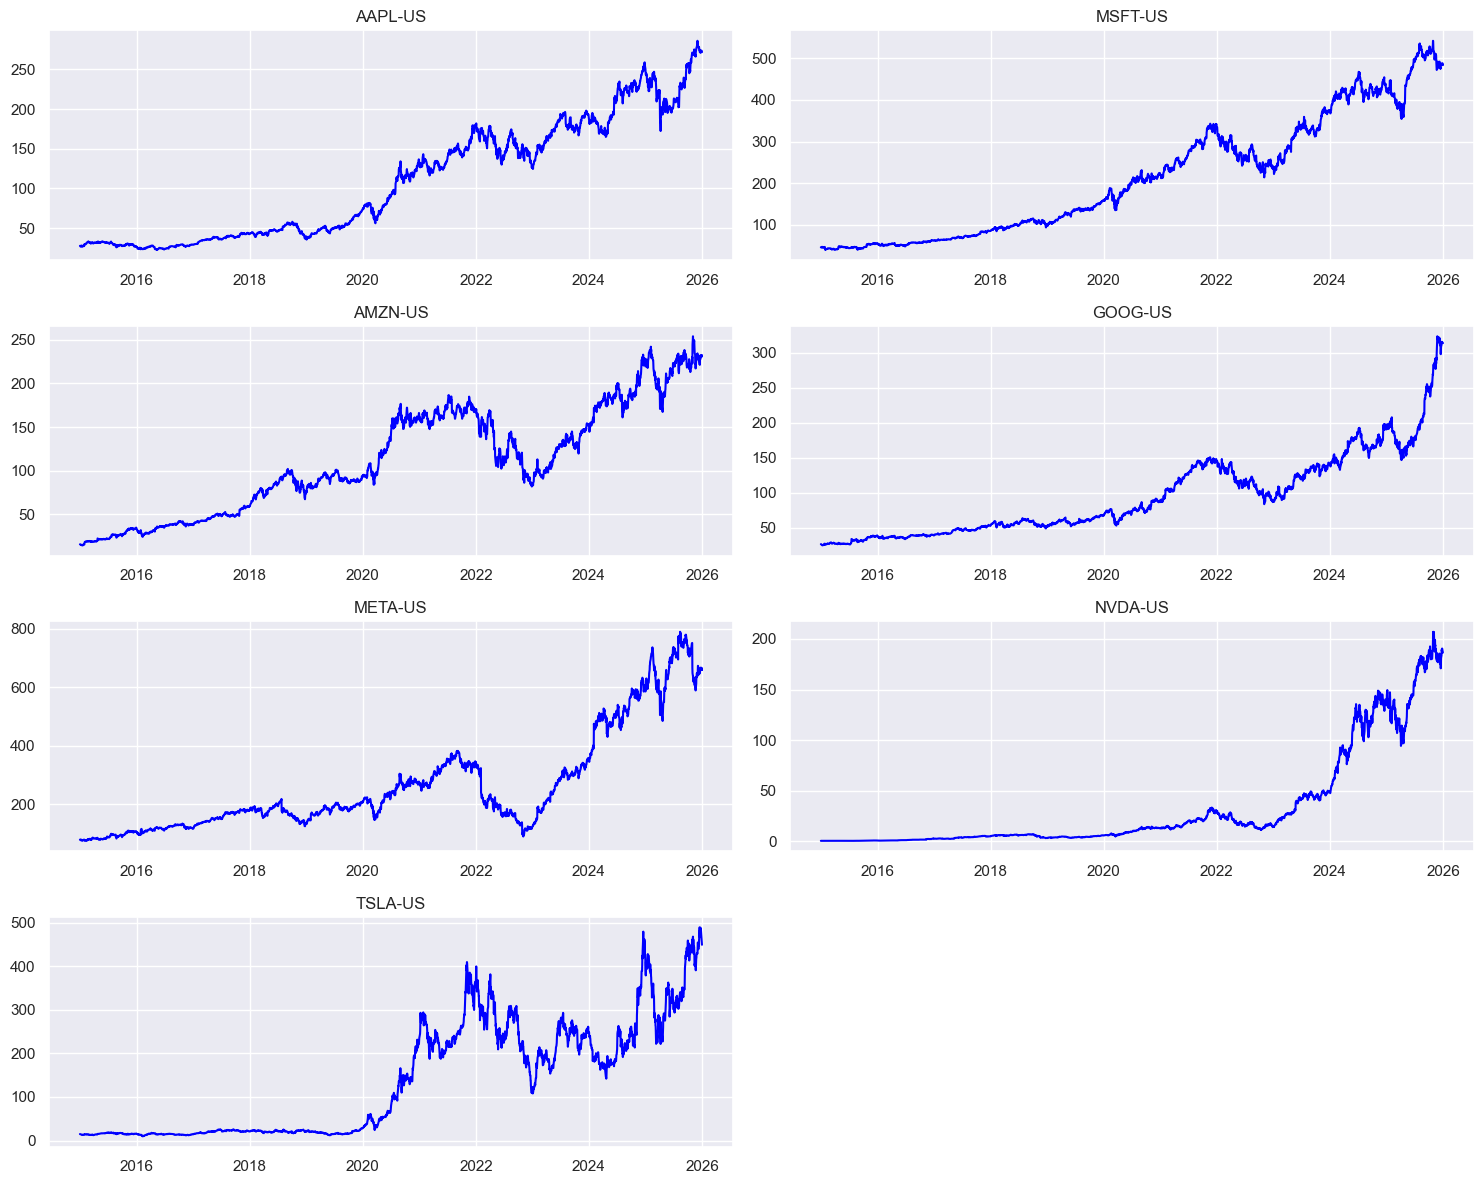

In [14]:
fig, axes = plt.subplots(4, 2, figsize=(15, 12))  # Figura con 4 filas y 2 columnas (8 huecos para 7 empresas)
axes = axes.flatten()  # Convierte la matriz 4x2 en lista plana para acceder con axes[i] en lugar de axes[0][0]

for i, symbol in enumerate(Magnificent_7):  # Recorremos las 7 empresas, i es el índice (0-6) y symbol el ticker
    datos = df_M7[df_M7['symbol'] == symbol]  # Filtramos los datos de esta empresa
    axes[i].plot(datos['date'], datos['price'], color = 'blue')  # Dibujamos la evolución del precio en azul
    axes[i].set_title(symbol)  # Título con el ticker de la empresa

axes[-1].set_visible(False)  # Ocultamos el hueco 8 que queda vacío al tener solo 7 empresas
plt.tight_layout()  # Ajusta márgenes para evitar solapamientos
plt.show()  # Mostramos la figura

**Dispersión de los retornos diarios de las Magnificent 7 (2015-2026)**

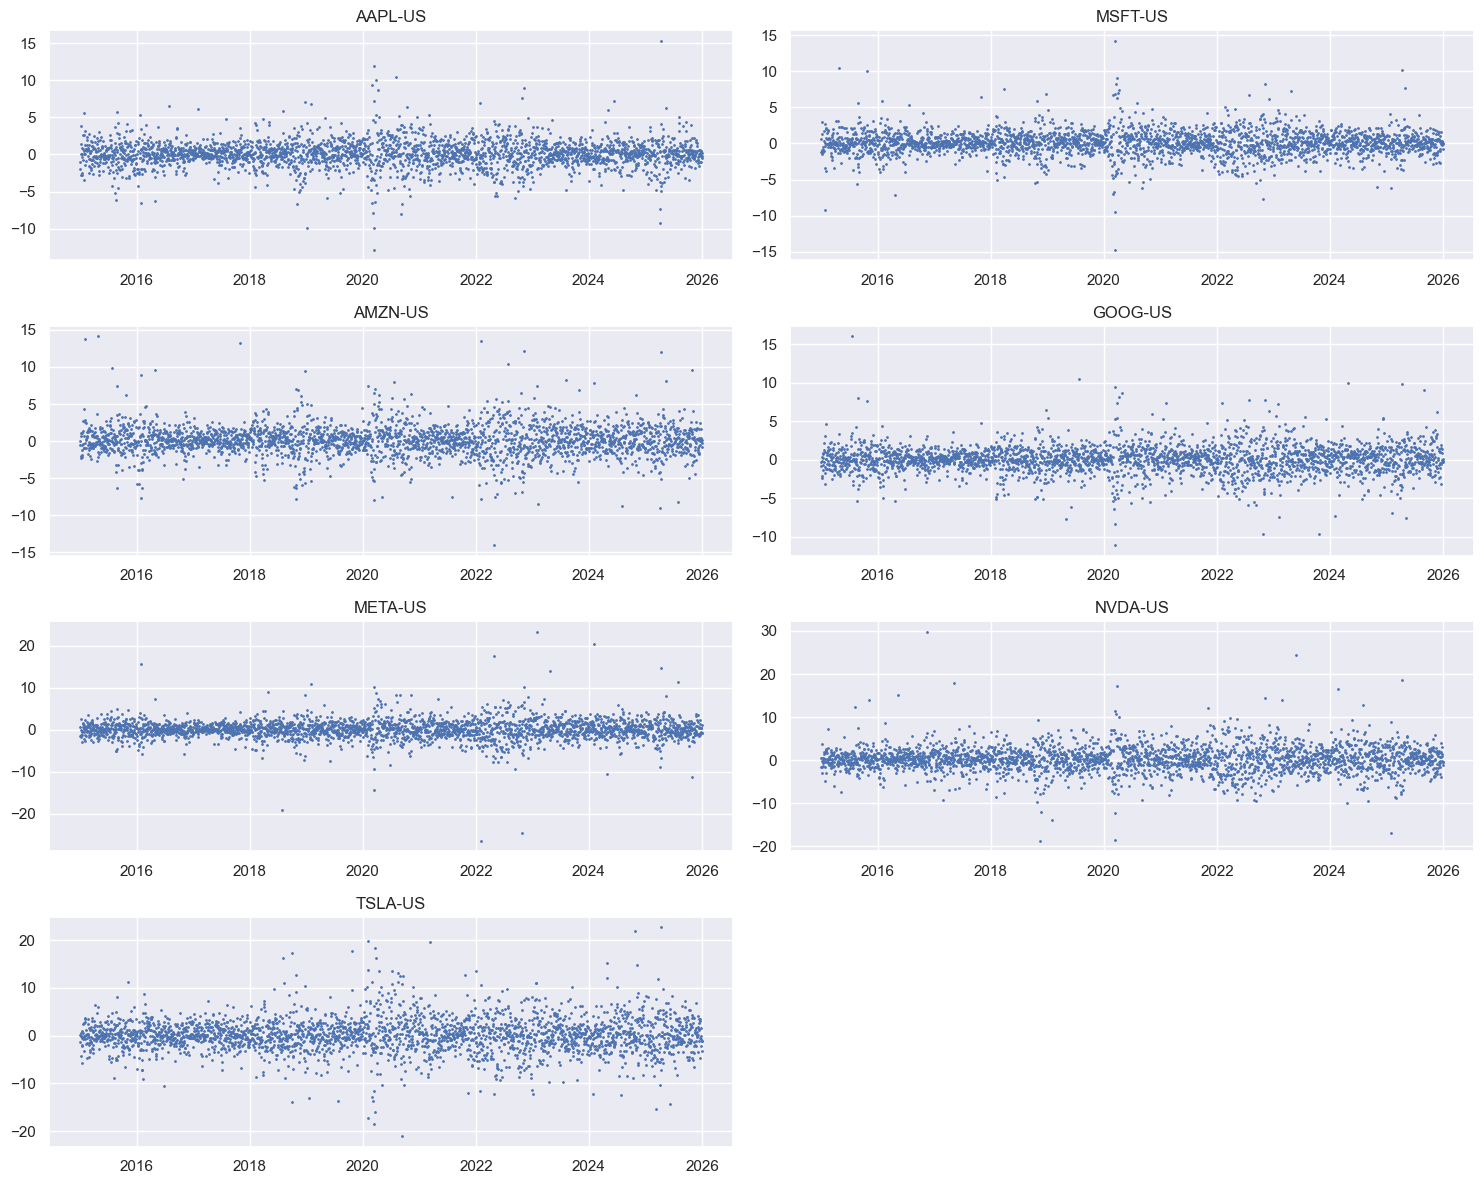

In [15]:
fig, axes = plt.subplots(4, 2, figsize=(15, 12))  # Figura con 4 filas y 2 columnas (8 huecos para 7 empresas)
axes = axes.flatten()                              # Convertimos la matriz 4x2 en lista plana para acceder con axes[i]

for i, symbol in enumerate(Magnificent_7): # Recorremos las 7 empresas
    datos = df_M7[df_M7['symbol'] == symbol]  # Filtramos los datos de esta empresa
    axes[i].scatter(datos['date'], datos['price_returns_div_received'], s=1)  # Dibujamos los retornos como puntos (s=1 tamaño mínimo para ver densidad)
    axes[i].set_title(symbol)    # Título con el ticker de la empresa

axes[-1].set_visible(False)  # Ocultamos el hueco 8 que queda vacío
plt.tight_layout()           # Ajusta márgenes para evitar solapamientos
plt.show()                   # Mostramos la figura

# 3. Split Train / Test

### Creación de los lags

Para la creación de los lags debemos tener en cuenta que en nuestro caso utilizamos los datos de los últimos 60 días para predecir el retorno acumulado dentro de 22 días. Predecimos el retorno acumulado porque el retorno de ese día no nos daría una información relevante para invertir.

**Creamos la variable target**

In [16]:
df_M7 = df_M7.sort_values(['symbol','date']) # Ordenamos los datos por empresa y en cada empresa por fecha de más antigua a más reciente

HORIZONTE = 22  # días de mercado del retorno acumulado que queremos predecir

def target_acumulado(x):
    x = x / 100 # Los retornos están en porcentaje, los pasamos a decimal
    resultado = pd.Series(1, index=x.index) # Creamos una serie de unos, uno por cada fila
    for lag in range(1, HORIZONTE + 1): # En cada iteración multiplicamos por el retorno del día siguiente
        resultado *= (1 + x.shift(-lag))
    return resultado - 1

df_M7['target'] = df_M7.groupby('symbol')['price_returns_div_received'].transform(target_acumulado)

# Introducimos fecha_fin_target para evitar data leakage: si la fecha de corte que ponemos para train es 2023-10-10 (anterior a esa fecha es train y posterior es test), e imaginamos el target de la fila 2023-09-28 como el target es a 22 días el retorno de 2023-10-28 se está calculando con los datos de test.
df_M7['fecha_fin_target'] = df_M7.groupby('symbol')['date'].shift(-HORIZONTE) # Para cada fila guarda la fecha del día t+22, es decir, el último día que necesita para calcular su target. Si esta fecha cae en el período de test, la fila se eliminará del train en el split para evitar leakage


**Creamos los lags**

In [17]:
for lag in range(1, 61):  # Iteramos de 1 a 60 para crear 60 variables de entrada (features)
    df_M7[f'lag_{lag}'] = df_M7.groupby('symbol')['price_returns_div_received'].shift(lag)  # lag_1 = retorno de ayer, lag_2 = retorno de hace 2 días... lag_60 = retorno de hace 60 días. El groupby evita que los lags de una empresa se mezclen con los de la siguiente

In [18]:
df_M7.head(5)

,symbol,date,price,price_returns_div_received,target,fecha_fin_target,lag_1,lag_2,lag_3,lag_4,...,lag_51,lag_52,lag_53,lag_54,lag_55,lag_56,lag_57,lag_58,lag_59,lag_60
id,,,,,,,,,,,,,,,,,,,,,
03783310,AAPL-US,2014-12-31,27.5950,-1.901883,0.074923,2015-02-03,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
03783310,AAPL-US,2015-01-02,27.3325,-0.951254,0.093570,2015-02-04,-1.901883,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
03783310,AAPL-US,2015-01-05,26.5625,-2.817160,0.133271,2015-02-05,-0.951254,-1.901883,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
03783310,AAPL-US,2015-01-06,26.5650,0.009418,0.123622,2015-02-06,-2.817160,-0.951254,-1.901883,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
03783310,AAPL-US,2015-01-07,26.9375,1.402223,0.115444,2015-02-09,0.009418,-2.817160,-0.951254,-1.901883,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
df_M7 = df_M7.dropna()
df_M7.head(5)

,symbol,date,price,price_returns_div_received,target,fecha_fin_target,lag_1,lag_2,lag_3,lag_4,...,lag_51,lag_52,lag_53,lag_54,lag_55,lag_56,lag_57,lag_58,lag_59,lag_60
id,,,,,,,,,,,,,,,,,,,,,
03783310,AAPL-US,2015-03-30,31.5925,2.531445,-0.009654,2015-04-30,-0.796843,0.697029,-2.612680,-0.408769,...,-0.381053,0.887871,-2.464068,0.107253,3.842223,1.402223,0.009418,-2.817160,-0.951254,-1.901883
03783310,AAPL-US,2015-03-31,31.1075,-1.535177,0.036326,2015-05-01,2.531445,-0.796843,0.697029,-2.612680,...,-2.714026,-0.381053,0.887871,-2.464068,0.107253,3.842223,1.402223,0.009418,-2.817160,-0.951254
03783310,AAPL-US,2015-04-01,31.0625,-0.144660,0.035815,2015-05-04,-1.535177,2.531445,-0.796843,0.697029,...,-0.777012,-2.714026,-0.381053,0.887871,-2.464068,0.107253,3.842223,1.402223,0.009418,-2.817160
03783310,AAPL-US,2015-04-02,31.3300,0.861168,0.003830,2015-05-05,-0.144660,-1.535177,2.531445,-0.796843,...,2.575719,-0.777012,-2.714026,-0.381053,0.887871,-2.464068,0.107253,3.842223,1.402223,0.009418
03783310,AAPL-US,2015-04-06,31.8375,1.619852,-0.018375,2015-05-06,0.861168,-0.144660,-1.535177,2.531445,...,0.763428,2.575719,-0.777012,-2.714026,-0.381053,0.887871,-2.464068,0.107253,3.842223,1.402223


### Split en Train y Test 80/20

In [20]:
FECHA_CORTE = pd.Timestamp('2023-10-10')  # Fecha que divide train y test (80/20 aproximado)

# Solo entran en train las filas cuyo target se realiza completamente antes del corte.
# Sin esto, las últimas ~22 filas de train tendrían targets calculados con retornos del test.
train = df_M7[df_M7['fecha_fin_target'] <= FECHA_CORTE]  # Train: filas cuyo t+22 cae antes del corte
test  = df_M7[df_M7['date'] > FECHA_CORTE]               # Test: filas posteriores al corte

# TimeSeriesSplit (LightGBM) y validation_split (LSTM) asumen orden cronológico estricto, por tanto, ordenamos por fecha.
train = train.sort_values(['date', 'symbol'])  # Ordenamos train por fecha
test  = test.sort_values(['date', 'symbol'])   # Ordenamos test por fecha

porcentaje_train = len(train) / len(df_M7) * 100  # Calculamos el % de filas en train
porcentaje_test  = len(test)  / len(df_M7) * 100  # Calculamos el % de filas en test
print(f'Split : {porcentaje_train:.1f}% / {porcentaje_test:.1f}%') # Imprimimos el split
print(f'Última fecha de train      : {train["date"].max().date()}') # Imprimimos la última fecha de train
print(f'Primera fecha de test      : {test["date"].min().date()}') # Imprimimos la primera fecha de test

Split : 79.2% / 20.0%
Última fecha de train      : 2023-09-08
Primera fecha de test      : 2023-10-11


In [21]:
lags = [f'lag_{i}' for i in range(1, 61)]  # Lista con los nombres de las 60 columnas de lags ['lag_1', 'lag_2', ..., 'lag_60']

X_train = train[lags] # Features de entrenamiento: los 60 lags de retornos pasados
y_train = train['target'] # Variable objetivo de entrenamiento: retorno acumulado a 22 días

X_test = test[lags] # Features de test: los 60 lags de retornos pasados
y_test = test['target'] # Variable objetivo de test: retorno acumulado a 22 días

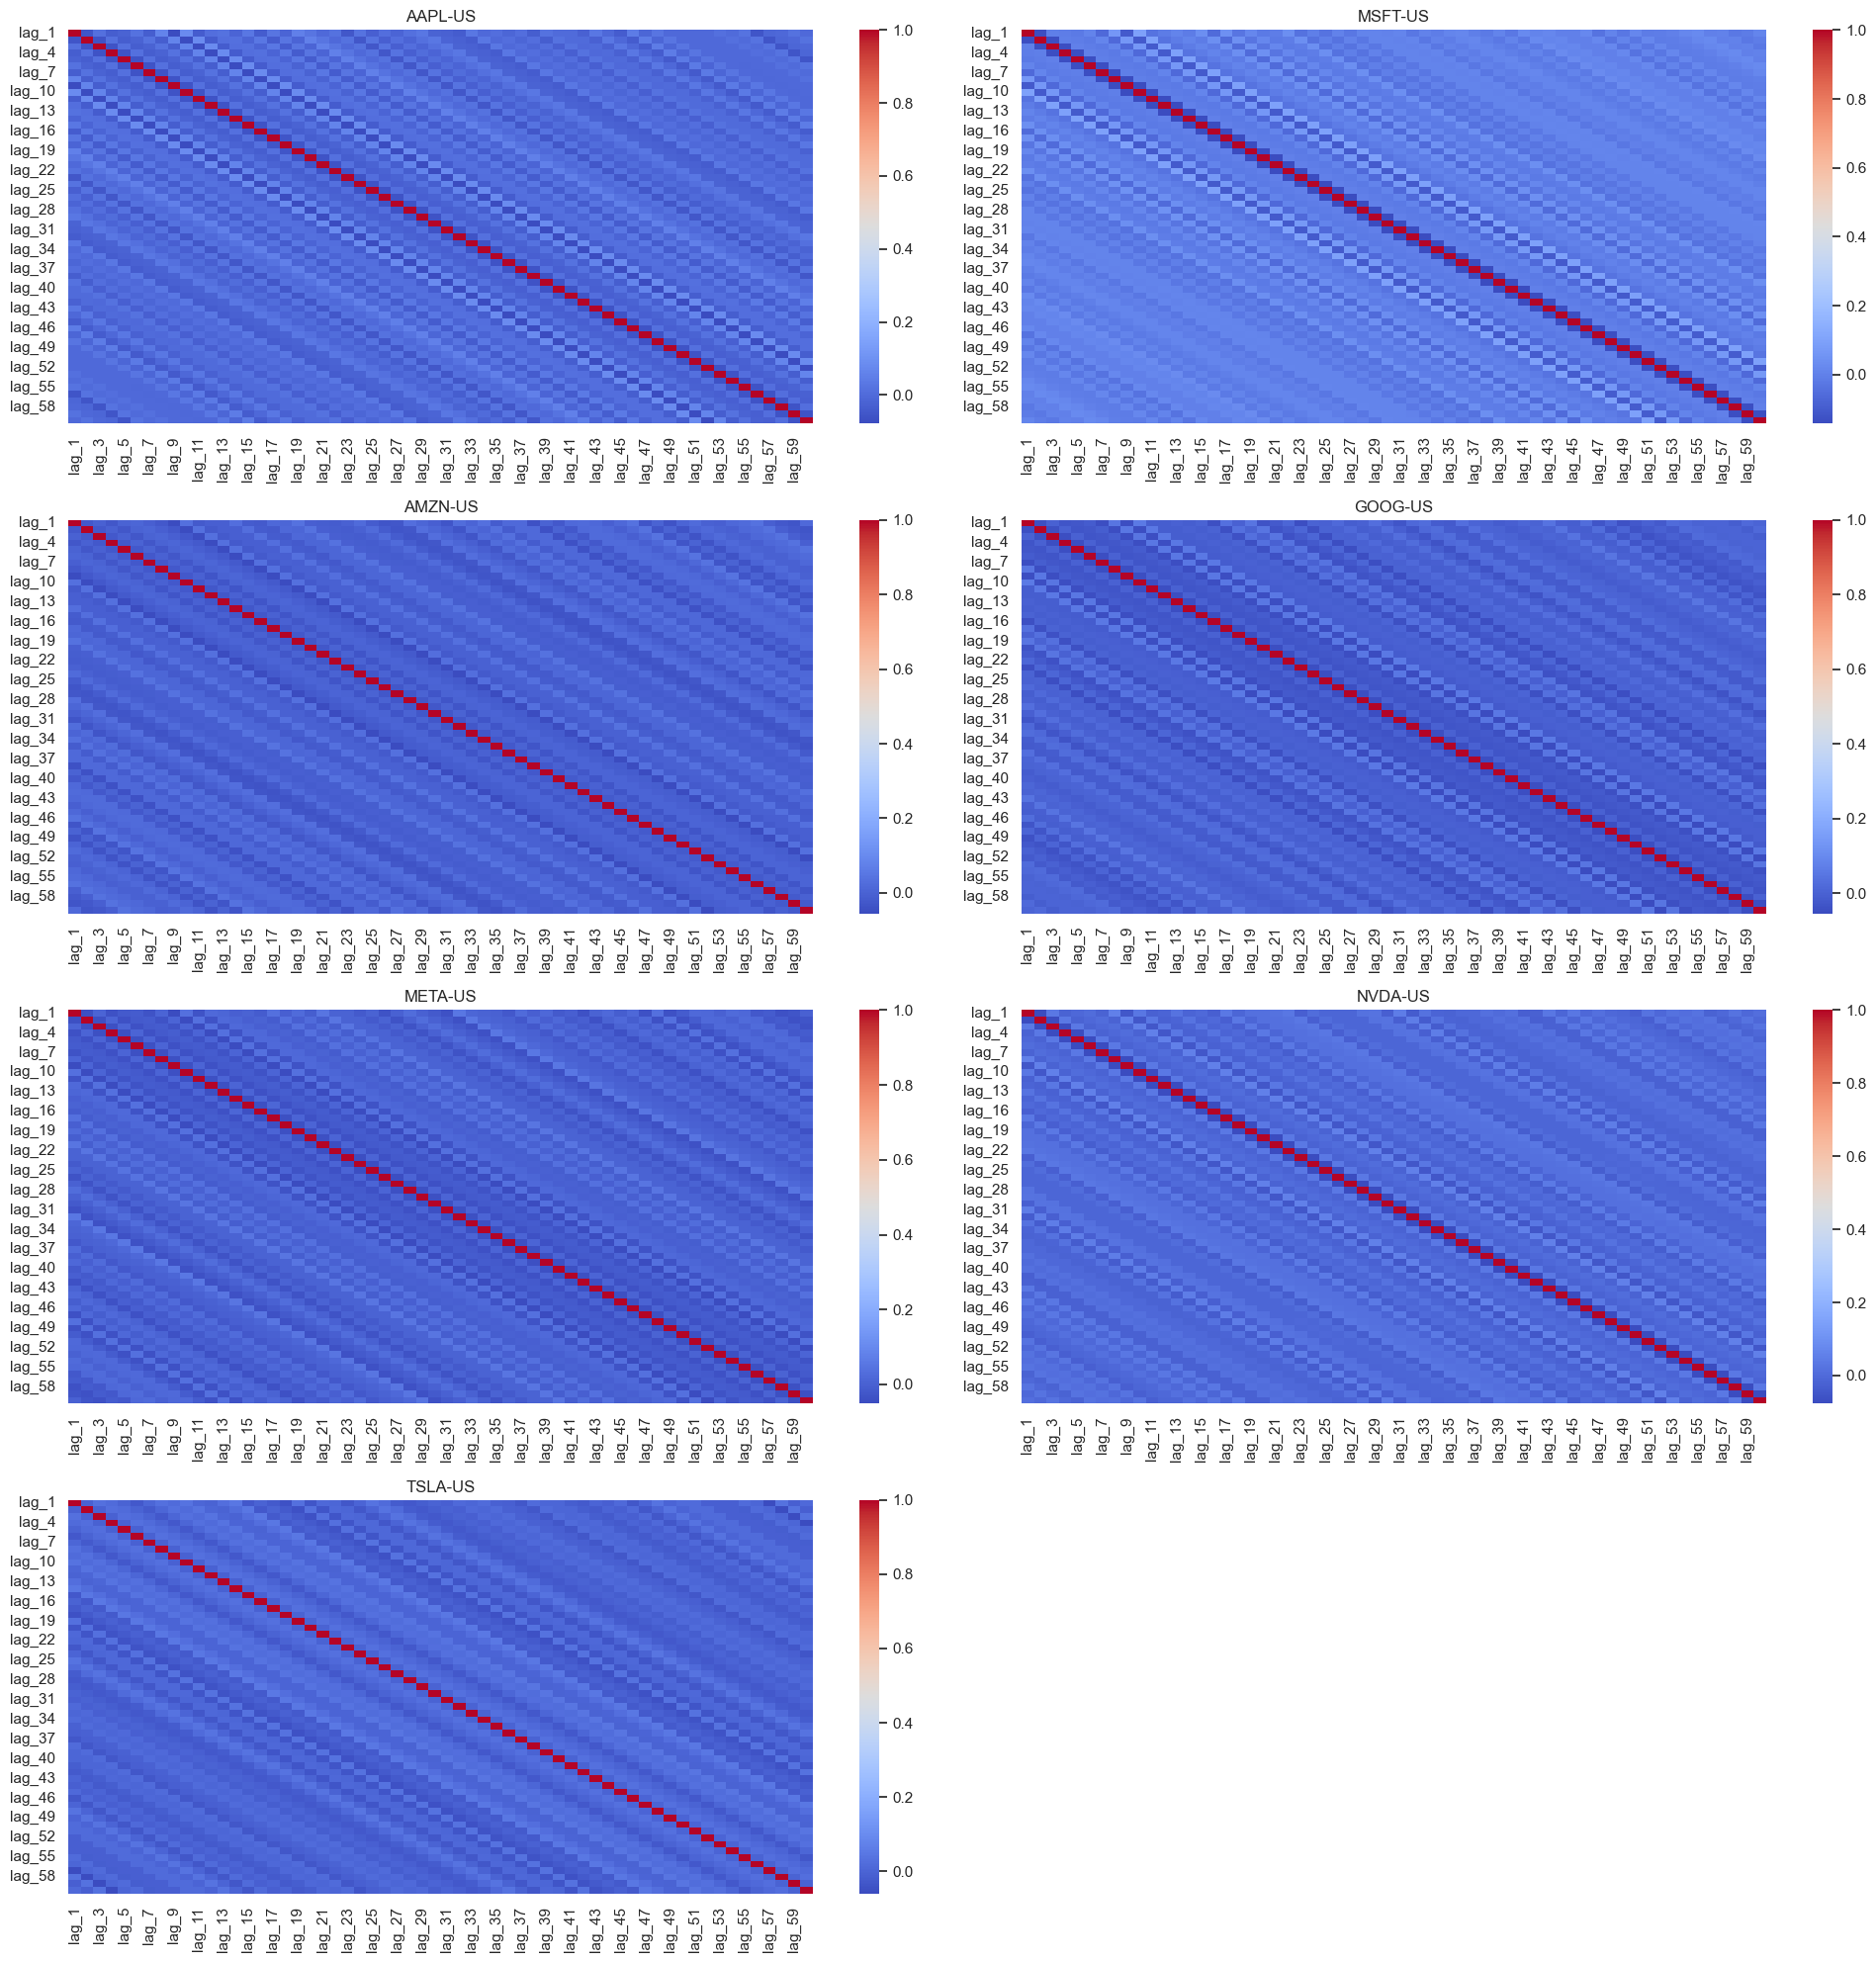

In [22]:
fig, axes = plt.subplots(4, 2, figsize=(20, 20))  # Figura con 4 filas y 2 columnas (8 huecos para 7 empresas)
axes = axes.flatten()  # Convertimos la matriz 4x2 en lista plana para acceder con axes[i]

for i, symbol in enumerate(Magnificent_7):  # Recorremos las 7 empresas
    corr = df_M7[df_M7['symbol'] == symbol][lags].corr()  # Calculamos la matriz de correlación entre los 60 lags de esta empresa
    sns.heatmap(corr, cmap='coolwarm', ax=axes[i])  # Dibujamos el heatmap: rojo = correlación alta, azul = correlación baja
    axes[i].set_title(symbol)  # Título con el ticker de la empresa

axes[-1].set_visible(False)  # Ocultamos el hueco 8 que queda vacío al tener solo 7 empresas
plt.tight_layout()  # Ajusta márgenes para evitar solapamientos
plt.show()  # Mostramos la figura

Observando la matriz de correlación de los lags se puede ver un patrón en la correlación de un lag y los lags a 8 y 10 días representado por las 2 diagonales paralelas en azul oscuro. De hecho, esa correlación es superior a la de un lag y sus 2 días posteriores. Esto podría reflejar los ciclos semanales del mercado.

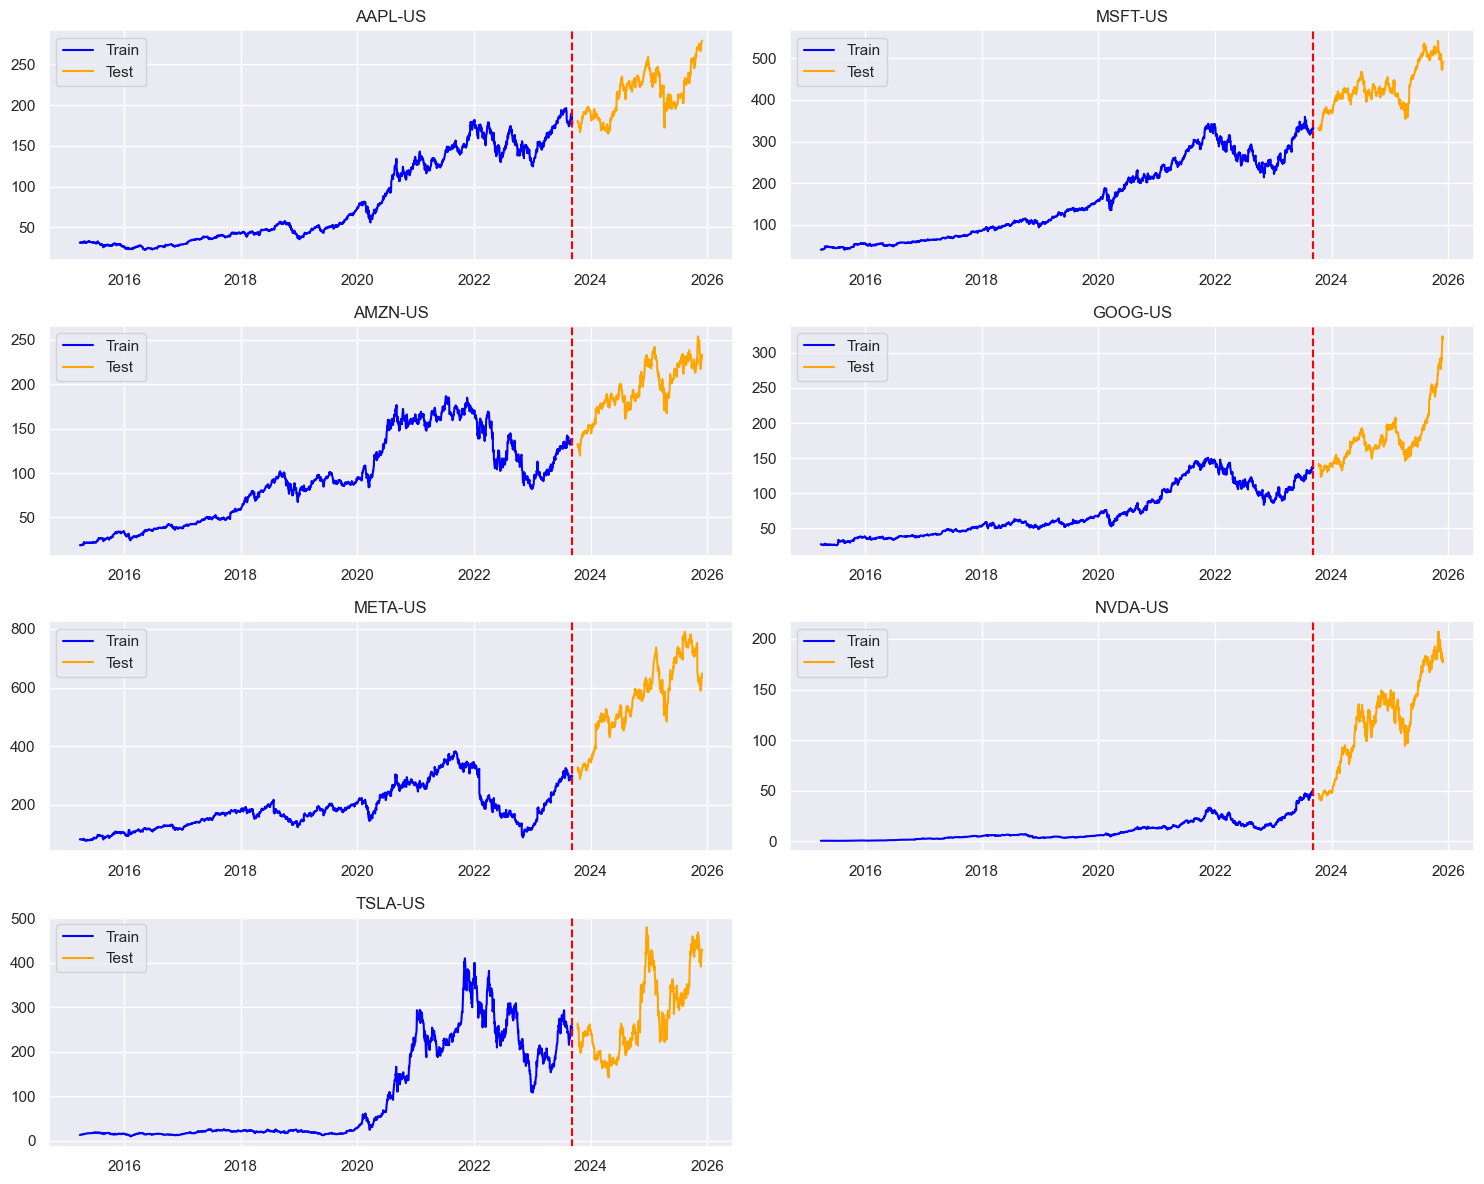

In [47]:
fig, axes = plt.subplots(4, 2, figsize=(15, 12))  # Figura con 4 filas y 2 columnas
axes = axes.flatten()  # Convertimos la matriz 4x2 en lista plana

for i, symbol in enumerate(Magnificent_7):  # Recorremos las 7 empresas
    datos_train = train[train['symbol'] == symbol]  # Filtramos datos de train de esta empresa
    datos_test  = test[test['symbol'] == symbol]    # Filtramos datos de test de esta empresa

    axes[i].plot(datos_train['date'], datos_train['price'], color='blue',   label='Train')    # Precio durante el train en azul
    axes[i].plot(datos_test['date'],  datos_test['price'],  color='orange', label='Test')     # Precio durante el test en naranja
    axes[i].axvline(x=pd.to_datetime('2023-09-08'), color='red', linestyle='--')              # Línea vertical roja marcando la fecha de corte
    axes[i].set_title(symbol)  # Título con el ticker
    axes[i].legend()           # Leyenda Train/Test

axes[-1].set_visible(False)  # Ocultamos el hueco 8 vacío
plt.tight_layout()           # Ajusta márgenes
plt.show()                   # Mostramos la figura

El gráfico muestra la evolución del precio como referencia visual de la división temporal. Las variables utilizadas por el modelo son los retornos diarios, no el precio absoluto.

### Normalización

In [24]:
scaler = StandardScaler()  # Inicializamos el scaler: resta la media y divide por la desviación típica de cada feature

X_train = scaler.fit_transform(X_train)  # Aprende la media y desviación típica del train y escala X_train (fit + transform)
X_test  = scaler.transform(X_test)       # Escala X_test usando la media y desviación típica del train, nunca del test para evitar leakage

Se utliza StandardScaler porque los retornos de las acciones tienen valores atípicos debido a las subidas y bajadas abruptas. MinMaxScaler toma el valor mínimo y máximo para comprimir los datos en un rango entre -1 y 1, si en el histórico hubo un cisne negro (bajada muy alta), MinMaxScaler utilizará ese dato como límite y el reste de variaciones perderán escala.

# Regresión Lineal

In [25]:
# Entrenamos
Regresion_lineal = LinearRegression() # Inicializamos el modelo de regresión lineal
Regresion_lineal.fit(X_train, y_train) # Entrenamos el modelo con los datos de train

# Predecimos
prediccion_test_RL = Regresion_lineal.predict(X_test)  # Generamos predicciones sobre el test

# Métricas
rmse = np.sqrt(mean_squared_error(y_test, prediccion_test_RL))  # Error cuadrático medio: penaliza más los errores grandes
mae  = mean_absolute_error(y_test, prediccion_test_RL)          # Error absoluto medio: más interpretable, en las mismas unidades que el target
r2   = r2_score(y_test, prediccion_test_RL)                     # R²: proporción de varianza explicada por el modelo (negativo = peor que predecir la media)

print(f'RMSE : {rmse:.4f}')
print(f'MAE  : {mae:.4f}')
print(f'R²   : {r2:.4f}')

RMSE : 0.1137
MAE  : 0.0822
R²   : -0.0281


# LightGBM

**RandomSearch**

In [26]:
param_grid = {
    'n_estimators'      : [300, 500, 700], # Número de árboles del ensemble
    'learning_rate'     : [0.01, 0.05], # Tasa de aprendizaje: cuánto contribuye cada árbol
    'max_depth'         : [2, 3, 4], # Profundidad máxima de cada árbol: controla complejidad
    'num_leaves'        : [10, 20, 30], # Número máximo de hojas por árbol
    'min_child_samples' : [50, 100, 200], # Mínimo de muestras por hoja: evita hojas con pocos datos
    'reg_alpha'         : [0.1, 0.3, 0.5, 1.0], # Regularización L1: puede llevar coeficientes a cero
    'reg_lambda'        : [0.5, 1.0, 2.0], # Regularización L2: penaliza coeficientes grandes
}

# TimeSeriesSplit entrena con datos anteriores y valida con posteriores
# El gap evita que el target de las últimas filas del train de cada fold invada su validación
tscv = TimeSeriesSplit(n_splits=5, gap=22 * 7)  # 5 folds temporales con gap de ~154 filas (22 días x 7 empresas)

random_search = RandomizedSearchCV(
    LGBMRegressor(verbose=-1),       # Modelo base: LightGBM en modo silencioso
    param_distributions = param_grid, # Espacio de búsqueda de hiperparámetros
    n_iter   = 20,                    # Número de combinaciones aleatorias a probar
    scoring  = 'neg_root_mean_squared_error',  # Métrica de evaluación: RMSE negativo (sklearn minimiza)
    cv       = tscv,                  # Validación cruzada temporal
    random_state = 42,                # Semilla para reproducibilidad
    n_jobs   = 1                      # Usa 1 solo núcleo de la CPU
)

random_search.fit(X_train, y_train)  # Lanzamos la búsqueda sobre los datos de train

print(f'Mejores parámetros : {random_search.best_params_}')  # Imprimimos la combinación ganadora

Mejores parámetros : {'reg_lambda': 0.5, 'reg_alpha': 0.3, 'num_leaves': 30, 'n_estimators': 300, 'min_child_samples': 100, 'max_depth': 2, 'learning_rate': 0.01}


**Entrenamos LightGBM**

In [27]:
# Entrenamos con los mejores parámetros
LightGBM = random_search.best_estimator_  # Recuperamos el modelo con la mejor combinación de hiperparámetros encontrada por RandomizedSearchCV

# Predecimos
prediccion_train_LGB = LightGBM.predict(X_train)  # Predicciones sobre train (para detectar overfitting)
prediccion_test_LGB  = LightGBM.predict(X_test)   # Predicciones sobre test (evaluación real del modelo)

# Métricas
rmse_train = np.sqrt(mean_squared_error(y_train, prediccion_train_LGB))  # RMSE train
mae_train  = mean_absolute_error(y_train, prediccion_train_LGB)          # MAE train
r2_train   = r2_score(y_train, prediccion_train_LGB)                     # R² train

rmse_test  = np.sqrt(mean_squared_error(y_test, prediccion_test_LGB))    # RMSE test
mae_test   = mean_absolute_error(y_test, prediccion_test_LGB)            # MAE test
r2_test    = r2_score(y_test, prediccion_test_LGB)                       # R² test

# Comparamos train vs test para detectar overfitting: si train >> test el modelo memoriza en lugar de generalizar
print(f'        Train       Test')
print(f'RMSE : {rmse_train:.4f}      {rmse_test:.4f}')
print(f'MAE  : {mae_train:.4f}      {mae_test:.4f}')
print(f'R²   : {r2_train:.4f}     {r2_test:.4f}')

        Train       Test
RMSE : 0.1167      0.1120
MAE  : 0.0815      0.0810
R²   : 0.0262     0.0032


# LSTM

**Pasamos los datos a 3D**

In [28]:
# Pasamos lo lags invertidos para que la lstm comience leyendo desde el lag hace 60 días hasta el de ayer, que es el órden cronológico natural
X_train_lstm = X_train[:, ::-1].reshape(X_train.shape[0], X_train.shape[1], 1)  # (muestras, 60 pasos, 1 feature)
X_test_lstm  = X_test[:, ::-1].reshape(X_test.shape[0],   X_test.shape[1],  1)  # Mismo reshape para el test

print(X_train_lstm.shape)  # Esperado: (n_train, 60, 1)
print(X_test_lstm.shape)   # Esperado: (n_test, 60, 1)

(14889, 60, 1)
(3752, 60, 1)


**RandomSearch**

In [29]:
def build_model(hp):  # hp es el objeto de Keras Tuner que gestiona los hiperparámetros a explorar
    modelo = Sequential()  # Inicializamos el modelo secuencial (capas apiladas una tras otra)
    units   = hp.Choice('units',         [32, 64, 128, 256])   # Número de unidades de la capa LSTM a explorar
    dropout = hp.Choice('dropout',       [0.1, 0.2, 0.3, 0.4]) # Tasa de dropout a explorar
    lr      = hp.Choice('learning_rate', [0.001, 0.01])         # Tasa de aprendizaje del optimizador a explorar

    modelo.add(LSTM(units, input_shape=(60, 1)))  # Capa LSTM: recibe secuencias de 60 pasos con 1 feature
    modelo.add(Dropout(dropout))                  # Dropout: desactiva aleatoriamente neuronas para evitar overfitting
    modelo.add(Dense(1))                          # Capa de salida: un único valor (retorno predicho)

    modelo.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='mse', metrics=['mae'])  # MSE como función de pérdida, MAE como métrica de seguimiento
    return modelo

tuner = kt.RandomSearch(
    build_model,
    objective  = 'val_loss',  # Minimizamos el MSE de validación
    max_trials = 20,          # Probamos 20 combinaciones aleatorias de hiperparámetros
    overwrite  = True,        # Sobreescribe resultados de búsquedas anteriores
    seed       = 42           # Semilla para reproducibilidad
)

early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)  # Para si val_loss no mejora en 5 epochs consecutivos y restaura los mejores pesos

# Lanzamos la búsqueda usando el último 10% del train como validación (en orden cronológico)
# shuffle=False es crítico: garantiza que la validación sean siempre los datos más recientes del train
tuner.search(
    X_train_lstm, y_train,
    epochs           = 20,    # Máximo de epochs por prueba
    batch_size       = 32,    # Muestras por actualización de pesos
    verbose          = 2,     # Muestra una línea por epoch
    validation_split = 0.1,   # Último 10% del train como validación
    shuffle          = False,  # Sin mezcla: respeta el orden temporal
    callbacks        = [early_stopping]
)

print(tuner.get_best_hyperparameters()[0].values)  # Imprimimos la combinación de hiperparámetros ganadora

Trial 20 Complete [00h 00m 49s]
val_loss: 0.03015557862818241

Best val_loss So Far: 0.021081626415252686
Total elapsed time: 00h 47m 45s
{'units': 256, 'dropout': 0.3, 'learning_rate': 0.01}


**Entrenamos LSTM**

In [30]:
# Definimos el modelo con los mejores hiperparámetros encontrados por el tuner (256 unidades, dropout=0.3, lr=0.01)
modelo_lstm = Sequential([
    LSTM(256, input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])),  # Capa LSTM con 256 unidades: recibe secuencias de (60 pasos, 1 feature)
    Dropout(0.3),  # Desactiva aleatoriamente el 30% de las neuronas en cada epoch para evitar overfitting
    Dense(1)       # Capa de salida: predice un único valor continuo (retorno acumulado a 22 días)
])

modelo_lstm.compile(
    optimizer = tf.keras.optimizers.Adam(0.01),  # Optimizador Adam con tasa de aprendizaje 0.01
    loss      = 'mse',   # Función de pérdida: MSE, consistente con el tuner
    metrics   = ['mae']  # Métrica de seguimiento: MAE, más interpretable financieramente
)

In [31]:
history = modelo_lstm.fit(
    X_train_lstm, y_train,
    validation_split = 0.1,   # Último 10% del train como validación (en orden cronológico)
    shuffle          = False,  # Sin mezcla: respeta el orden temporal de las series
    epochs           = 20,     # Máximo de epochs (el early stopping parará antes si no mejora)
    batch_size       = 32,     # Muestras por actualización de pesos
    verbose          = 2,      # Muestra una línea por epoch
    callbacks        = [early_stopping]  # Para si val_loss no mejora en 5 epochs consecutivos y restaura los mejores pesos
)

Epoch 1/20
419/419 - 20s - 48ms/step - loss: 0.0307 - mae: 0.1253 - val_loss: 0.0210 - val_mae: 0.1042
Epoch 2/20
419/419 - 18s - 43ms/step - loss: 0.0260 - mae: 0.1048 - val_loss: 0.0670 - val_mae: 0.2211
Epoch 3/20
419/419 - 18s - 43ms/step - loss: 0.0171 - mae: 0.0955 - val_loss: 0.0564 - val_mae: 0.1969
Epoch 4/20
419/419 - 18s - 44ms/step - loss: 0.0164 - mae: 0.0930 - val_loss: 0.0534 - val_mae: 0.1898
Epoch 5/20
419/419 - 18s - 43ms/step - loss: 0.0184 - mae: 0.0980 - val_loss: 0.0690 - val_mae: 0.2212
Epoch 6/20
419/419 - 18s - 43ms/step - loss: 0.0167 - mae: 0.0937 - val_loss: 0.0499 - val_mae: 0.1808


In [32]:
prediccion_train_lstm = modelo_lstm.predict(X_train_lstm, verbose=0)  # Predicciones sobre train
prediccion_test_lstm  = modelo_lstm.predict(X_test_lstm,  verbose=0)  # Predicciones sobre test

rmse_train = np.sqrt(mean_squared_error(y_train, prediccion_train_lstm))  # RMSE train
rmse_test  = np.sqrt(mean_squared_error(y_test,  prediccion_test_lstm))   # RMSE test
mae_train  = mean_absolute_error(y_train, prediccion_train_lstm)          # MAE train
mae_test   = mean_absolute_error(y_test,  prediccion_test_lstm)           # MAE test
r2_train   = r2_score(y_train, prediccion_train_lstm)                     # R² train
r2_test    = r2_score(y_test,  prediccion_test_lstm)                      # R² test

print(f'{"":10}  {"Train":}       {"Test":}')
print(f'{"RMSE":10} {rmse_train:.4f}   {rmse_test:.4f}')
print(f'{"MAE":10} {mae_train:.4f}   {mae_test:.4f}')
print(f'{"R²":10} {r2_train:.4f}    {r2_test:.4f}')

            Train       Test
RMSE       0.1317   0.1235
MAE        0.0994   0.0959
R²         -0.2398    -0.2123


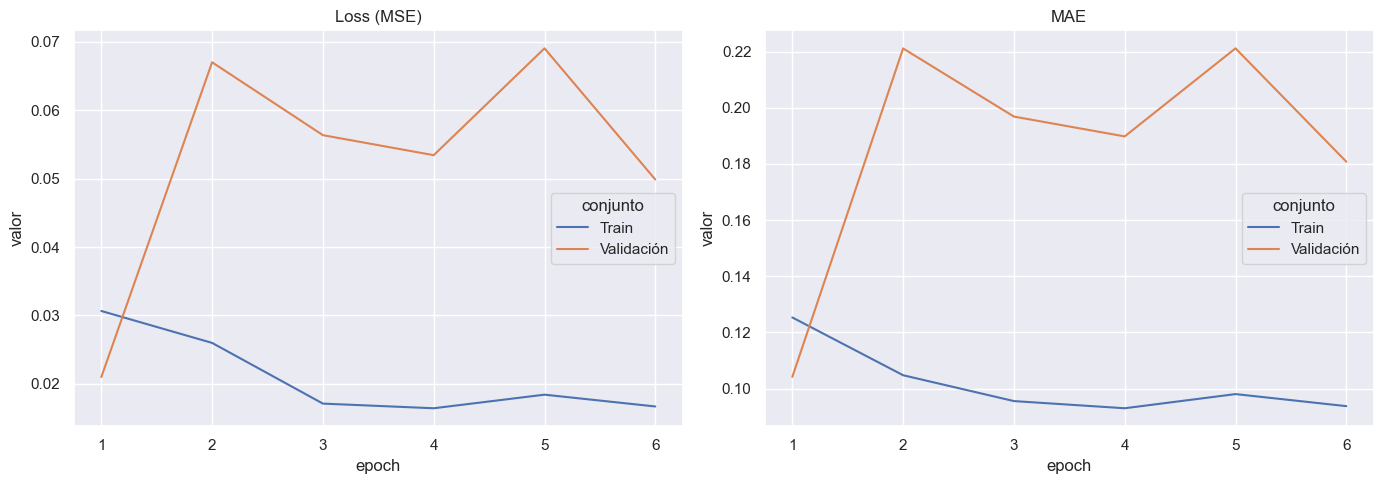

In [33]:
epochs = range(1, len(history.history['loss']) + 1)  # Secuencia de epochs ejecutados (puede ser menor que 20 si early stopping paró antes)

# Construimos un DataFrame con MSE (loss) de train y validación
loss_df = pd.DataFrame({
    'epoch'    : list(epochs) * 2,                                        # Repetimos los epochs dos veces (una para train, otra para validación)
    'valor'    : history.history['loss'] + history.history['val_loss'],   # MSE de train seguido de MSE de validación
    'conjunto' : ['Train'] * len(epochs) + ['Validación'] * len(epochs)  # Etiqueta para distinguir ambas curvas
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))  # Figura con 2 gráficos en horizontal

sns.lineplot(data=loss_df, x='epoch', y='valor', hue='conjunto', ax=axes[0])  # Curva de MSE por epoch
axes[0].set_title('Loss (MSE)')  # Si val_loss sube mientras train_loss baja hay overfitting

# Construimos un DataFrame con MAE de train y validación
mae_df = pd.DataFrame({
    'epoch'    : list(epochs) * 2,                                      # Repetimos los epochs dos veces
    'valor'    : history.history['mae'] + history.history['val_mae'],   # MAE de train seguido de MAE de validación
    'conjunto' : ['Train'] * len(epochs) + ['Validación'] * len(epochs) # Etiqueta para distinguir ambas curvas
})

sns.lineplot(data=mae_df, x='epoch', y='valor', hue='conjunto', ax=axes[1])  # Curva de MAE por epoch
axes[1].set_title('MAE')  # Error medio en las mismas unidades que el target (retorno decimal)

plt.tight_layout()  # Ajusta márgenes para evitar solapamientos
plt.show()          # Mostramos la figura

# Modelo NAIVE

In [34]:
y_pred_naive = np.zeros(len(y_test))  # El modelo naive predice siempre retorno 0: asume que el mercado no sube ni baja

rmse_naive = np.sqrt(mean_squared_error(y_test, y_pred_naive)) # RMSE naive
mae_naive  = mean_absolute_error(y_test, y_pred_naive) # MAE naive
r2_naive   = r2_score(y_test, y_pred_naive) # R² naive

print(f'RMSE : {rmse_naive:.4f}')
print(f'MAE  : {mae_naive:.4f}')
print(f'R²   : {r2_naive:.4f}')

RMSE : 0.1180
MAE  : 0.0856
R²   : -0.1065


# Resultados

### Tabla comparativa Métricas

| Modelo           | RMSE   | MAE    | R²      |
|------------------|--------|--------|---------|
| Naive            | 0.1180 | 0.0856 | -0.1065 |
| Regresión Lineal | 0.1137 | 0.0822 | -0.0281 |
| LightGBM         | 0.1120 | 0.0810 | 0.0032  |
| LSTM             | 0.1235 | 0.0959 | -0,2123 |

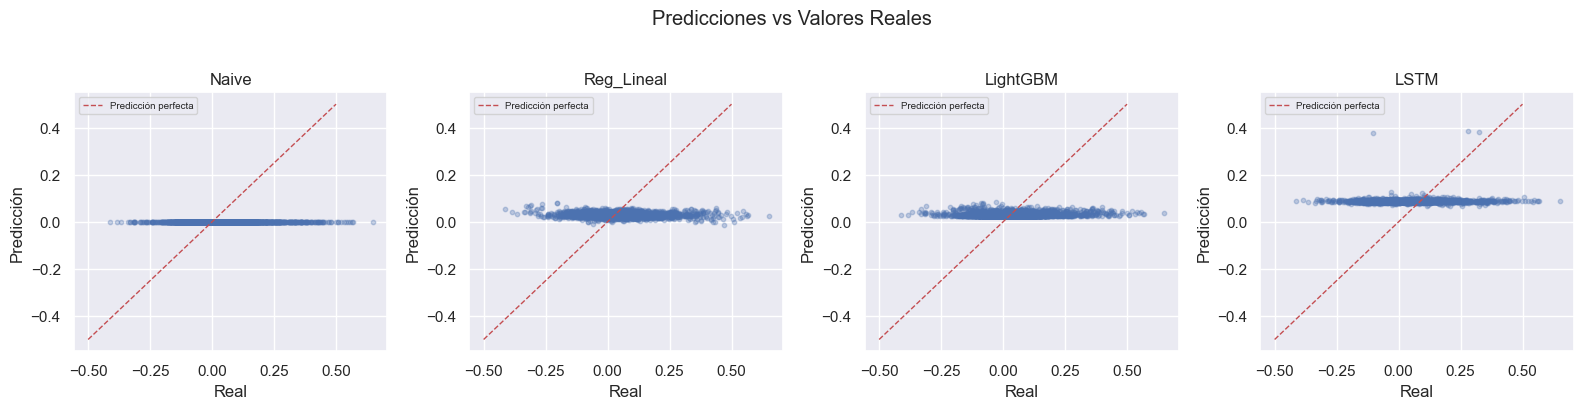

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))  # Figura con 4 gráficos en horizontal, uno por modelo
modelos = ['Naive', 'Reg_Lineal', 'LightGBM', 'LSTM']                                          # Nombres de los modelos
preds   = [y_pred_naive, prediccion_test_RL, prediccion_test_LGB, prediccion_test_lstm.flatten()]  # Predicciones de cada modelo

for i, (modelo, pred) in enumerate(zip(modelos, preds)):  # Recorremos cada modelo y sus predicciones
    axes[i].scatter(y_test, pred, alpha=0.3, s=10)  # Nube de puntos: eje X = real, eje Y = predicción (alpha=0.3 para ver densidad)
    axes[i].plot([-0.5, 0.5], [-0.5, 0.5], 'r--', linewidth=1, label='Predicción perfecta')  # Línea roja diagonal: si los puntos la siguen el modelo predice perfectamente
    axes[i].set_title(modelo)    # Título con el nombre del modelo
    axes[i].set_xlabel('Real')   # Eje X: valor real del retorno
    axes[i].set_ylabel('Predicción')  # Eje Y: valor predicho por el modelo
    axes[i].legend(fontsize=7)   # Leyenda de la línea roja

plt.suptitle('Predicciones vs Valores Reales', y=1.02)  # Título general para los 4 gráficos
plt.tight_layout()                                        # Ajusta márgenes para evitar solapamientos
plt.savefig('scatter_modelos.png', dpi=150)              # Guarda la figura en disco a 150 dpi
plt.show()                                                # Mostramos la figura

### Predicción del retorno acumulado por empresa

In [36]:
print(df_M7['symbol'].unique())

['AAPL-US' 'AMZN-US' 'GOOG-US' 'META-US' 'MSFT-US' 'NVDA-US' 'TSLA-US']


In [37]:
resultados = pd.DataFrame({
    'fecha'     : test['date'].values, # Fecha de cada observación del test
    'symbol'    : test['symbol'].values, # Ticker de la empresa
    'Naive'     : y_pred_naive, # Predicción del modelo naive (siempre 0)
    'Reg_Lineal': prediccion_test_RL, # Predicción de la regresión lineal
    'LightGBM'  : prediccion_test_LGB, # Predicción de LightGBM
    'LSTM'      : prediccion_test_lstm.flatten(), # Predicción de la LSTM (flatten convierte (n,1) a (n,))
    'Real'      : y_test.values # Retorno real acumulado a 22 días
})

print(resultados[resultados['symbol'] == 'AAPL-US'].head(20))

         fecha   symbol  Naive  Reg_Lineal  LightGBM      LSTM      Real
0   2023-10-11  AAPL-US    0.0    0.029183  0.026539  0.088465  0.038042
7   2023-10-12  AAPL-US    0.0    0.029444  0.026539  0.086799  0.023950
14  2023-10-13  AAPL-US    0.0    0.025775  0.026539  0.087153  0.049378
21  2023-10-16  AAPL-US    0.0    0.029307  0.026539  0.089479  0.053335
28  2023-10-17  AAPL-US    0.0    0.028171  0.026539  0.088056  0.072279
35  2023-10-18  AAPL-US    0.0    0.024654  0.026539  0.089313  0.080154
42  2023-10-19  AAPL-US    0.0    0.025153  0.026539  0.089064  0.092537
49  2023-10-20  AAPL-US    0.0    0.024982  0.026539  0.088290  0.104150
56  2023-10-23  AAPL-US    0.0    0.020762  0.026539  0.090343  0.107262
63  2023-10-24  AAPL-US    0.0    0.018577  0.026539  0.087872  0.096717
70  2023-10-25  AAPL-US    0.0    0.017779  0.026539  0.087582  0.110663
77  2023-10-26  AAPL-US    0.0    0.019405  0.026539  0.089954  0.142340
84  2023-10-27  AAPL-US    0.0    0.020051  0.02653

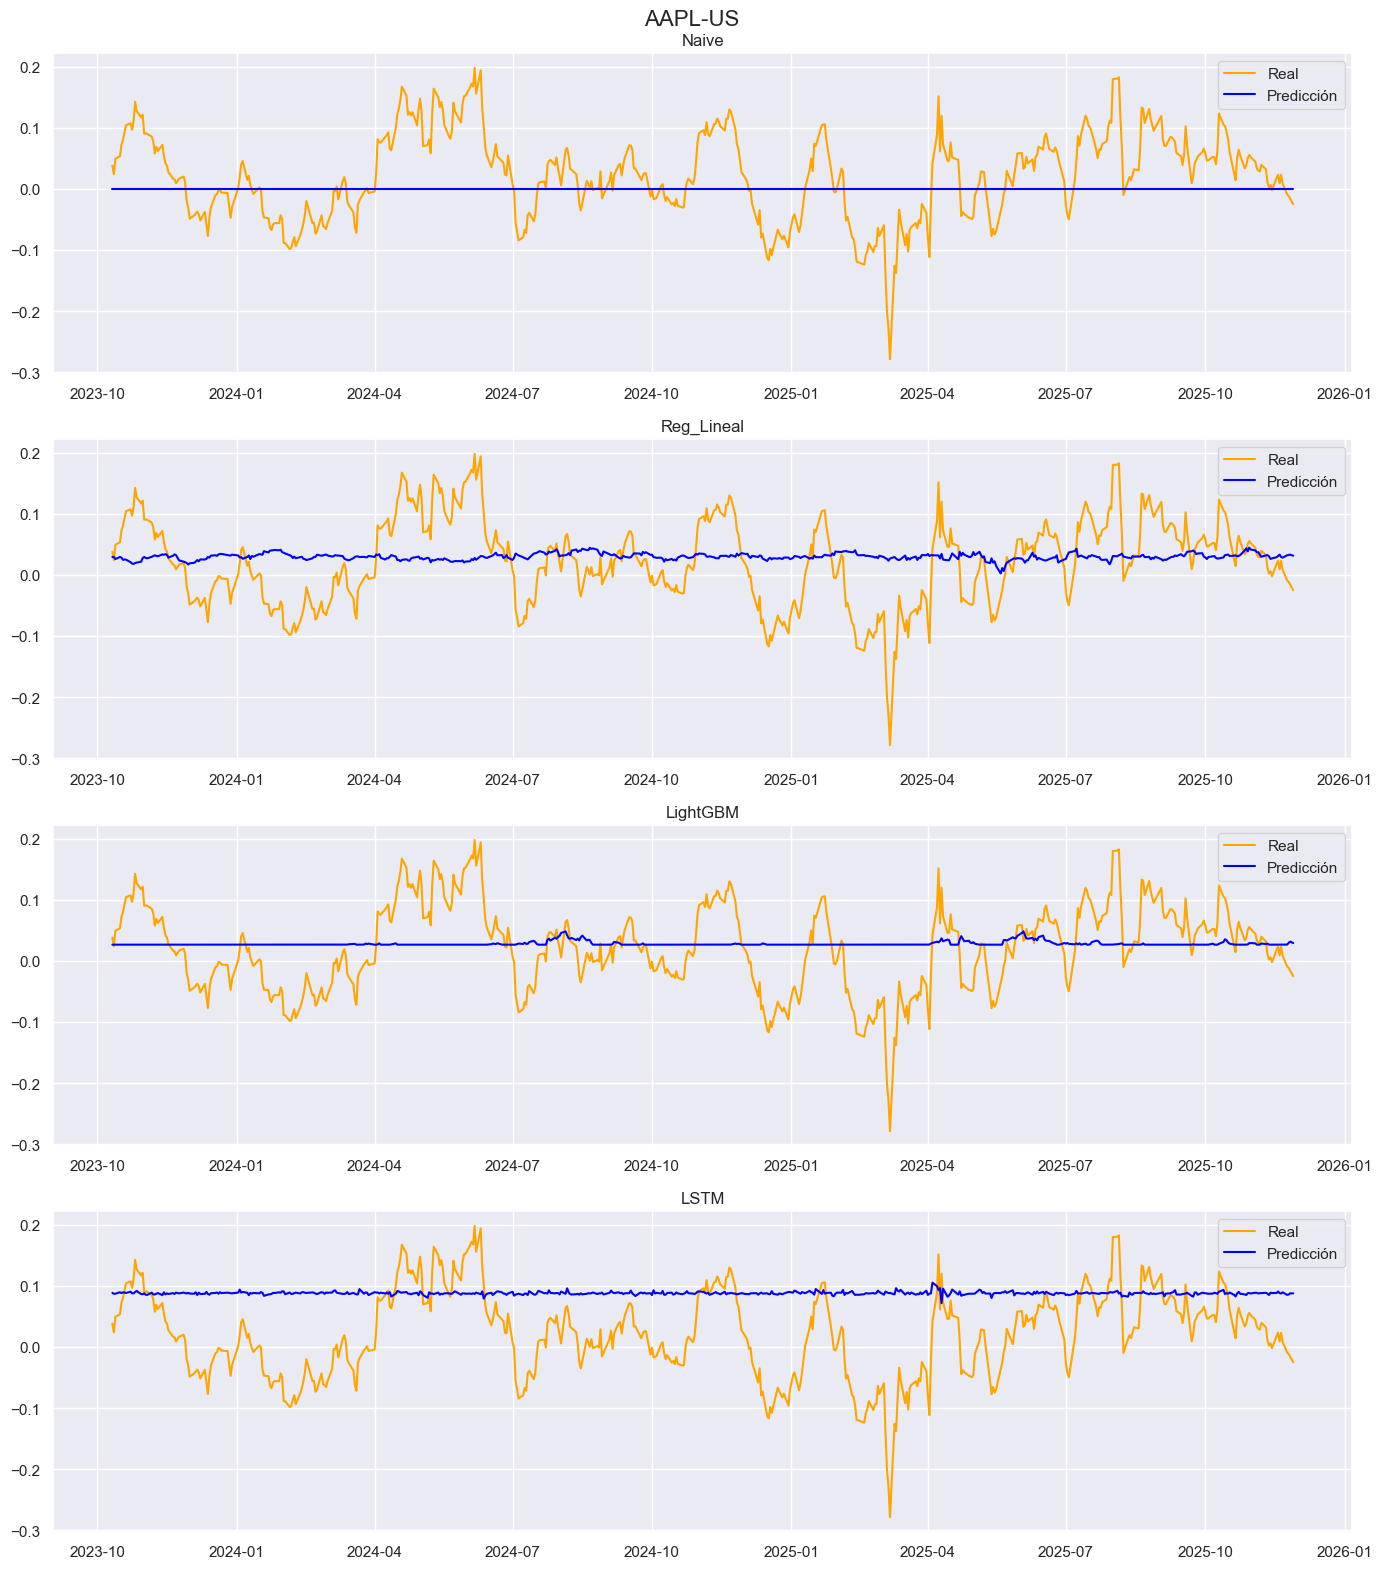

In [38]:
empresa = 'AAPL-US'  # Empresa a visualizar

fig, axes = plt.subplots(4, 1, figsize=(14, 16)) # Figura con 4 gráficos apilados verticalmente, uno por modelo
fig.suptitle(empresa, fontsize=16) # Título general con el ticker de la empresa

modelos = ['Naive', 'Reg_Lineal', 'LightGBM', 'LSTM'] # Lista de modelos a comparar
datos   = resultados[resultados['symbol'] == empresa] # Filtramos los resultados de Apple

for i, modelo in enumerate(modelos):  # Recorremos cada modelo
    axes[i].plot(datos['fecha'], datos['Real'],  color='orange', label='Real')        # Retorno real en naranja
    axes[i].plot(datos['fecha'], datos[modelo],  color='blue',   label='Predicción')  # Predicción del modelo en azul
    axes[i].set_title(modelo)  # Título con el nombre del modelo
    axes[i].legend()           # Leyenda Real/Predicción

plt.tight_layout()  # Ajusta márgenes para evitar solapamientos
plt.show()          # Mostramos la figura

### Predicción del retorno acumulado medio

In [39]:
# Agrupamos por fecha y calculamos la media de predicciones y retorno real entre las 7 empresas
resultados_media = resultados.groupby('fecha')[['Naive', 'Reg_Lineal', 'LightGBM', 'LSTM', 'Real']].mean().reset_index()

print(resultados_media.head(20))  # Verificamos que la agregación tiene sentido

        fecha  Naive  Reg_Lineal  LightGBM      LSTM      Real
0  2023-10-11    0.0    0.032256  0.035949  0.087210  0.005274
1  2023-10-12    0.0    0.033692  0.035951  0.085909  0.010960
2  2023-10-13    0.0    0.028099  0.034580  0.088375  0.055170
3  2023-10-16    0.0    0.034358  0.032180  0.090965  0.038708
4  2023-10-17    0.0    0.031980  0.032940  0.086014  0.050249
5  2023-10-18    0.0    0.033511  0.034778  0.089230  0.072838
6  2023-10-19    0.0    0.030887  0.032760  0.091590  0.102720
7  2023-10-20    0.0    0.027965  0.035326  0.090674  0.121175
8  2023-10-23    0.0    0.025393  0.034587  0.091090  0.108141
9  2023-10-24    0.0    0.024281  0.032466  0.086261  0.090367
10 2023-10-25    0.0    0.024872  0.033856  0.086544  0.130658
11 2023-10-26    0.0    0.024614  0.031503  0.093937  0.175007
12 2023-10-27    0.0    0.024510  0.030951  0.092387  0.144985
13 2023-10-30    0.0    0.025707  0.032400  0.085692  0.120276
14 2023-10-31    0.0    0.025757  0.031362  0.086698  0

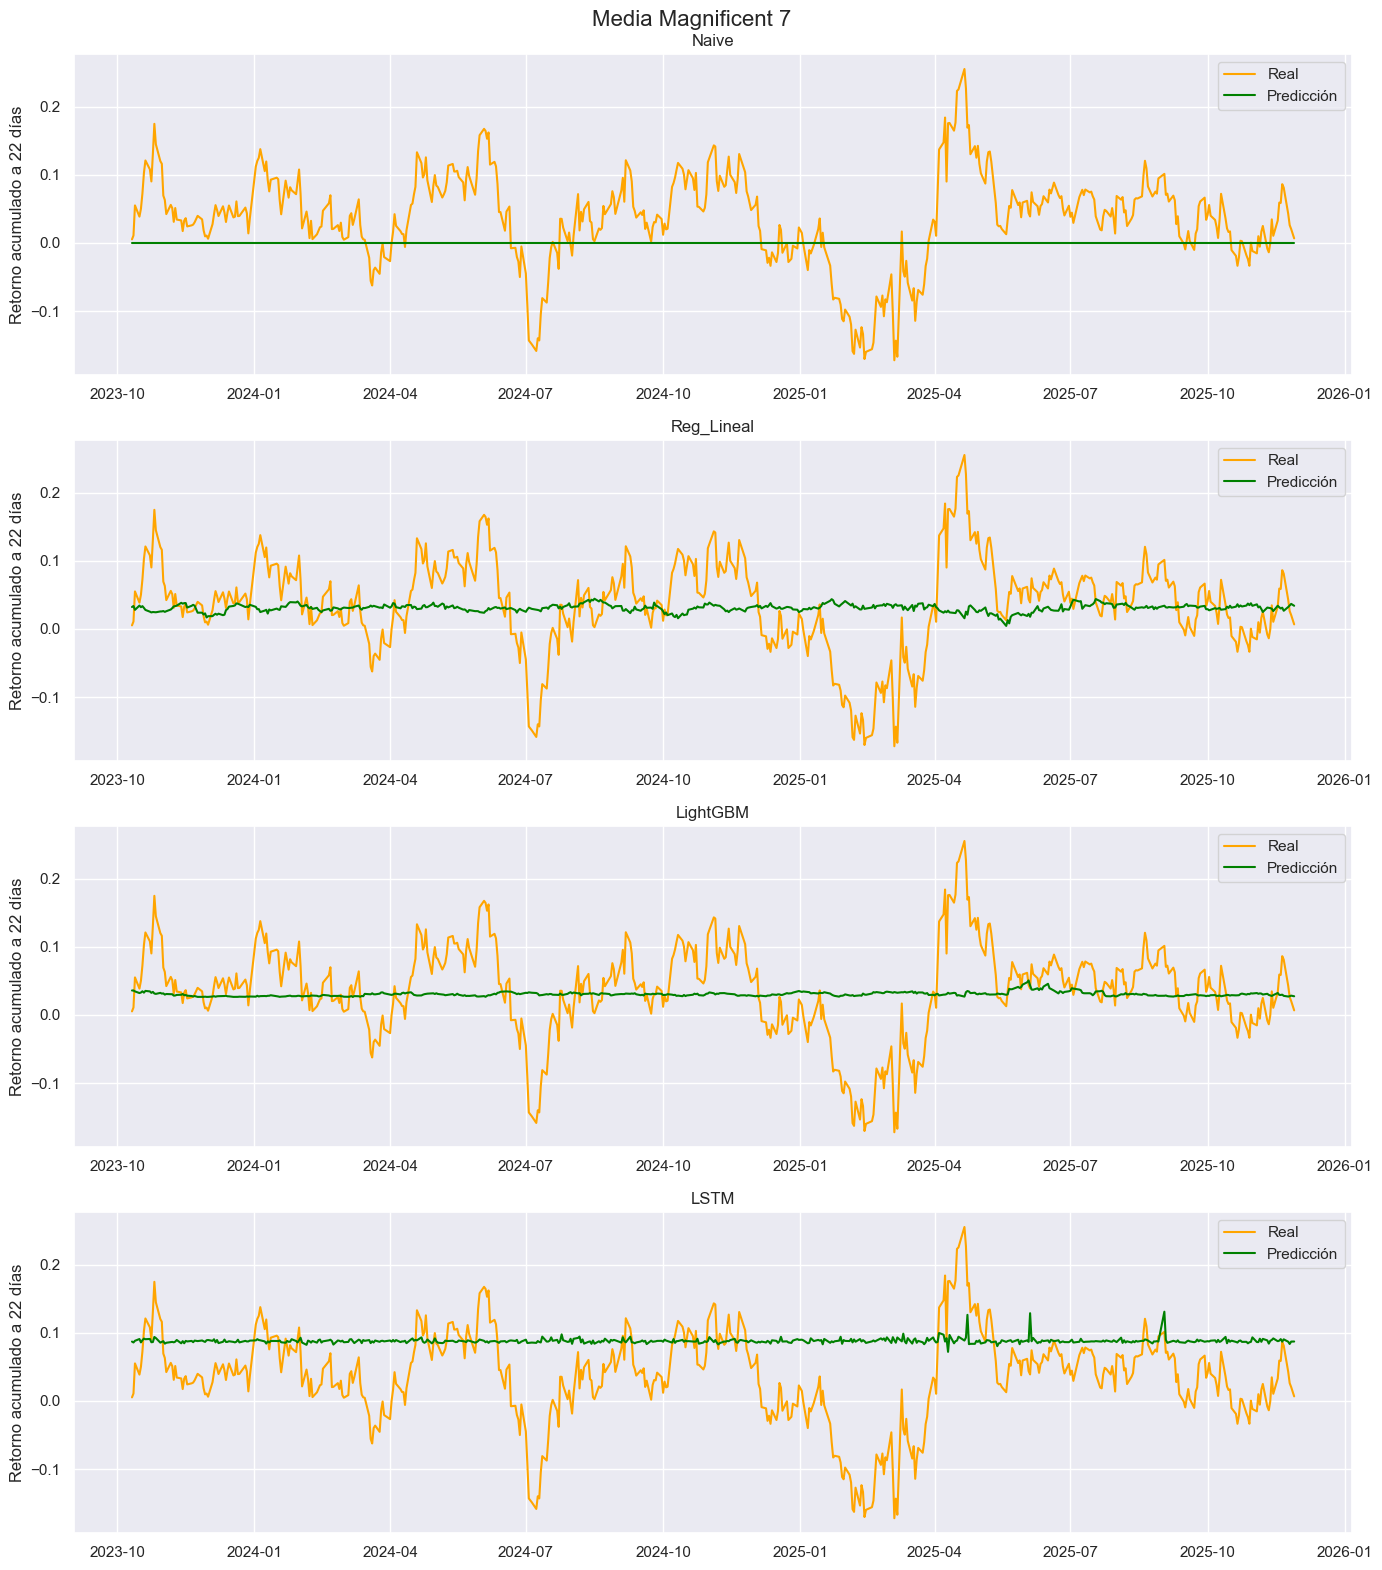

In [40]:
fig, axes = plt.subplots(4, 1, figsize=(14, 16))  # Figura con 4 gráficos apilados verticalmente, uno por modelo
fig.suptitle('Media Magnificent 7', fontsize=16)   # Título general: media de las 7 empresas

modelos = ['Naive', 'Reg_Lineal', 'LightGBM', 'LSTM']  # Lista de modelos a comparar

for i, modelo in enumerate(modelos):  # Recorremos cada modelo
    axes[i].plot(resultados_media['fecha'], resultados_media['Real'],   color='orange', label='Real') # Retorno real medio de las 7 empresas en naranja
    axes[i].plot(resultados_media['fecha'], resultados_media[modelo],   color='green',  label='Predicción') # Predicción media del modelo en verde
    axes[i].set_title(modelo) # Título con el nombre del modelo
    axes[i].set_ylabel('Retorno acumulado a 22 días') # Eje Y: unidades del target
    axes[i].legend() # Leyenda Real/Predicción

plt.tight_layout() # Ajusta márgenes para evitar solapamientos
plt.show() # Mostramos la figura

# Backtesting

**Definición de las funciones**

In [41]:
# Definimos la lista de lags que usaremos como variables de entrada
LAGS = [f'lag_{i}' for i in range(1, 61)]

# FUNCIÓN 1: Prepara los datos de una ventana temporal
def preparar_datos(df_ventana):
    X        = df_ventana[LAGS].values     # Seleccionamos las columnas de lags como variables X
    y        = df_ventana['target'].values  # Seleccionamos el target: retorno acumulado a 22 días
    scaler   = StandardScaler()            # Creamos el scaler
    X_scaled = scaler.fit_transform(X)     # Lo entrenamos y aplicamos SOLO con los datos de esta ventana para evitar leakage
    return X_scaled, y, scaler             # Devolvemos X escalado, y, y el scaler (necesario para escalar el test)

# FUNCIÓN 2: Entrena LightGBM con los mejores hiperparámetros encontrados por RandomizedSearchCV
def entrenar_modelo(X_train, y_train):
    modelo = LGBMRegressor(
        reg_lambda        = 0.5,   # Regularización L2: penaliza coeficientes grandes
        reg_alpha         = 0.3,   # Regularización L1: puede llevar coeficientes a cero
        num_leaves        = 30,    # Número máximo de hojas por árbol
        n_estimators      = 300,   # Número de árboles del ensemble
        min_child_samples = 100,   # Mínimo de muestras por hoja: evita hojas con pocos datos
        max_depth         = 2,     # Profundidad máxima de cada árbol: controla complejidad
        learning_rate     = 0.01,  # Tasa de aprendizaje: cuánto contribuye cada árbol
        verbose           = -1     # Sin output durante el entrenamiento
    )
    modelo.fit(X_train, y_train)  # Entrenamos el modelo con los datos de esta ventana
    return modelo

# FUNCIÓN 3: Genera predicciones sobre datos nuevos
def predecir(modelo, scaler, df_test):
    X_test = scaler.transform(df_test[LAGS].values)  # Escalamos el test con el scaler del train de esta ventana
    return modelo.predict(X_test)                     # Generamos predicciones y devolvemos el resultado

**Generamos fechas del backtesting**

In [42]:
fecha_inicio_bt = pd.Timestamp('2023-10-01')  # Fecha de inicio del backtesting, si usamos 2023-09-08 que es la fecha en la que acaba train en el split fijo va a empezar en esta fecha porque freq='MS' asique empieza el primer día del mes siguiente, es decir, el 2023-10-01

# Fecha en la que termina el backtesting (último dato disponible)
fecha_fin_bt = df_M7['date'].max()

# Generamos una fecha por cada mes entre el inicio y el fin
fechas_corte = pd.date_range(start=fecha_inicio_bt, end=fecha_fin_bt, freq='MS') # MS = Month Start genera una fecha por mes cogiendo el primer día de cada mes

# Mostramos las fechas generadas para comprobar que son correctas
print(fechas_corte)

DatetimeIndex(['2023-10-01', '2023-11-01', '2023-12-01', '2024-01-01',
               '2024-02-01', '2024-03-01', '2024-04-01', '2024-05-01',
               '2024-06-01', '2024-07-01', '2024-08-01', '2024-09-01',
               '2024-10-01', '2024-11-01', '2024-12-01', '2025-01-01',
               '2025-02-01', '2025-03-01', '2025-04-01', '2025-05-01',
               '2025-06-01', '2025-07-01', '2025-08-01', '2025-09-01',
               '2025-10-01', '2025-11-01'],
              dtype='datetime64[ns]', freq='MS')


**Bucle del backtesting**

In [43]:
# Ventana de entrenamiento en días naturales: 365 días garantizan ~1.600 filas por ventana proporcionando suficiente historia reciente para que LightGBM aprenda patrones estables
VENTANA_DIAS = 365

resultados_bt = []  # Lista vacía donde iremos guardando los resultados de cada mes

for fecha_corte in fechas_corte:  # Recorremos cada fecha de corte mensual

    fecha_inicio_train = fecha_corte - pd.Timedelta(days=VENTANA_DIAS)  # Inicio de la ventana: 365 días antes del corte
    fecha_fin_test     = fecha_corte + pd.offsets.MonthEnd(1)           # Fin del mes de predicción: último día del mes siguiente al corte

    # Train: datos dentro de la ventana cuyo target está completamente realizado antes del corte
    # fecha_fin_target < fecha_corte evita que el modelo se entrene con retornos del mes que predice
    train_bt = df_M7[(df_M7['date']            >= fecha_inicio_train) &
                     (df_M7['fecha_fin_target'] <  fecha_corte)]

    test_bt = df_M7[(df_M7['date'] >= fecha_corte) &
                    (df_M7['date'] <= fecha_fin_test)]  # Test: días del mes siguiente al corte

    if len(train_bt) == 0 or len(test_bt) == 0:  # Si alguna ventana está vacía saltamos este mes
        continue

    X_train, y_train, scaler = preparar_datos(train_bt)        # Escalamos y preparamos el train de esta ventana
    modelo                   = entrenar_modelo(X_train, y_train) # Entrenamos un modelo nuevo para esta ventana
    preds                    = predecir(modelo, scaler, test_bt) # Generamos predicciones sobre el mes de test

    for i, (_, fila) in enumerate(test_bt.iterrows()):  # Guardamos cada predicción con su contexto
        resultados_bt.append({
            'fecha'      : fila['date'],
            'symbol'     : fila['symbol'],
            'prediccion' : preds[i],
            'real'       : fila['target'],                           # Retorno acumulado real a 22 días
            'price'      : fila['price'],
            'ret_diario' : fila['price_returns_div_received'] / 100  # Retorno diario con dividendos en decimal
        })

df_bt = pd.DataFrame(resultados_bt)  # Convertimos la lista de resultados en un DataFrame
print(df_bt.head(20))                 # Verificamos que los resultados tienen sentido


        fecha   symbol  prediccion      real   price  ret_diario
0  2023-10-02  AAPL-US    0.033528  0.001266  173.75    0.014836
1  2023-10-03  AAPL-US    0.041510  0.029989  172.40   -0.007770
2  2023-10-04  AAPL-US    0.037340  0.017218  173.66    0.007309
3  2023-10-05  AAPL-US    0.039247  0.024698  174.91    0.007198
4  2023-10-06  AAPL-US    0.045254  0.024396  177.49    0.014750
5  2023-10-09  AAPL-US    0.053332  0.021789  178.99    0.008451
6  2023-10-10  AAPL-US    0.048441  0.022535  178.39   -0.003352
7  2023-10-11  AAPL-US    0.048953  0.038042  179.80    0.007904
8  2023-10-12  AAPL-US    0.050018  0.023950  180.71    0.005061
9  2023-10-13  AAPL-US    0.052711  0.049378  178.85   -0.010293
10 2023-10-16  AAPL-US    0.050462  0.053335  178.72   -0.000727
11 2023-10-17  AAPL-US    0.050883  0.072279  177.15   -0.008785
12 2023-10-18  AAPL-US    0.042272  0.080154  175.84   -0.007395
13 2023-10-19  AAPL-US    0.041903  0.092537  175.46   -0.002161
14 2023-10-20  AAPL-US   

Al usar MontEnd(1) en fecha_fin_test encontramos un problema: los targets a 22 días de mercado de meses consecutivos se solapan temporalmente, reduciendo la independencia estadística entre períodos de evaluación del backtesting. Esto no constituye leakage en sentido estricto, ya que no introduce información futura en las features del modelo."

**Métricas**

In [44]:
# Calculamos las métricas del backtesting comparando predicciones contra valores reales
rmse_bt = np.sqrt(mean_squared_error(df_bt['real'], df_bt['prediccion']))  # RMSE: penaliza más los errores grandes
mae_bt  = mean_absolute_error(df_bt['real'], df_bt['prediccion'])          # MAE: error medio en las mismas unidades que el target (retorno decimal)
r2_bt   = r2_score(df_bt['real'], df_bt['prediccion'])                     # R²: proporción de varianza explicada (negativo = peor que predecir siempre la media)

print(f'RMSE : {rmse_bt:.4f}')
print(f'MAE  : {mae_bt:.4f}')
print(f'R²   : {r2_bt:.4f}')

RMSE : 0.1133
MAE  : 0.0828
R²   : -0.0250


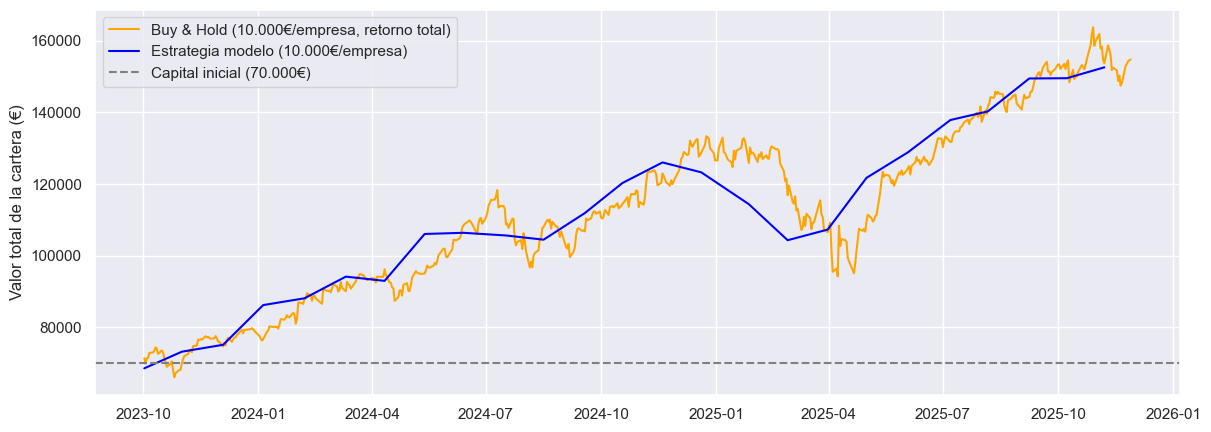

In [45]:
INVERSION_INICIAL = 10000  # euros por empresa
COSTE_TRANSACCION = 0.001  # 0.1% por operación (entrada o salida)

# ============================================================
# BUY & HOLD (retorno TOTAL, con dividendos, igual que la estrategia)
# ============================================================

df_bt = df_bt.sort_values(['symbol', 'fecha'])

# Valor de la cartera por empresa: 10.000€ x producto acumulado de (1 + retorno diario)
df_bt['valor_buyhold'] = df_bt.groupby('symbol')['ret_diario'] \
                              .transform(lambda r: INVERSION_INICIAL * (1 + r).cumprod())

# ============================================================
# ESTRATEGIA MODELO
# ============================================================

# Cogemos una fila de cada 22 por empresa (filas 0, 22, 44... = bloques no solapados)
# Nota: se evita groupby().apply() porque en pandas >= 2.2 elimina la columna de agrupación
df_bt['n_dia'] = df_bt.groupby('symbol').cumcount()
df_periodos = df_bt[df_bt['n_dia'] % 22 == 0].copy()

# Señal en t: si el modelo predice retorno positivo compramos (1), si no guardamos cash (0)
df_periodos['señal'] = (df_periodos['prediccion'] > 0).astype(int)

df_periodos['retorno_periodo'] = df_periodos['señal'] * df_periodos['real']

# Calculamos el valor de la cartera acumulado para cada empresa por separado
resultados_modelo = []

for empresa in df_periodos['symbol'].unique():
    df_empresa = df_periodos[df_periodos['symbol'] == empresa].sort_values('fecha')

    valor = INVERSION_INICIAL
    señal_anterior = 0  # empezamos en cash

    for _, fila in df_empresa.iterrows():
        # Coste de transacción cada vez que cambiamos de posición (compra o venta)
        if fila['señal'] != señal_anterior:
            valor = valor * (1 - COSTE_TRANSACCION)
        señal_anterior = fila['señal']

        # Aplicamos el retorno del período (0 si estamos en cash)
        valor = valor * (1 + fila['retorno_periodo'])

        resultados_modelo.append({
            'fecha'  : fila['fecha'],
            'symbol' : empresa,
            'valor'  : valor
        })

df_modelo = pd.DataFrame(resultados_modelo)

# ============================================================
# AGREGACIÓN: .sum() en ambas para comparar la cartera total (70.000€ inicial)
# ============================================================

buyhold_fecha = df_bt.groupby('fecha')['valor_buyhold'].sum().reset_index().sort_values('fecha')
modelo_fecha  = df_modelo.groupby('fecha')['valor'].sum().reset_index().sort_values('fecha')

# ============================================================
# GRÁFICO
# ============================================================

plt.figure(figsize=(14, 5))
plt.plot(buyhold_fecha['fecha'], buyhold_fecha['valor_buyhold'], label='Buy & Hold (10.000€/empresa, retorno total)', color='orange')
plt.plot(modelo_fecha['fecha'],  modelo_fecha['valor'],          label='Estrategia modelo (10.000€/empresa)', color='blue')
plt.axhline(y=7 * INVERSION_INICIAL, color='gray', linestyle='--', label='Capital inicial (70.000€)')
plt.ylabel('Valor total de la cartera (€)')
plt.legend()
plt.show()

Dado que el modelo predice retorno positivo en la totalidad de los períodos evaluados, la señal de inversión es siempre 1, lo que hace que la estrategia del modelo sea equivalente a un buy & hold actualizado cada 22 días. Por ello, esta curva no se incluye en el gráfico al ser visualmente indistinguible de la estrategia del modelo.

In [46]:
# Miramos los períodos donde el modelo tomó decisiones para una empresa concreta
empresa = 'AAPL-US'

# Filtramos los períodos de Apple ordenados por fecha
df_check = df_periodos[df_periodos['symbol'] == empresa].sort_values('fecha').copy()

# Calculamos el capital acumulado empezando en 10.000€ (sin costes, solo para inspección)
capital = INVERSION_INICIAL
capitales = []

for _, fila in df_check.iterrows():
    # Tras la corrección ya no hay NaN: señal y retorno están en la misma fila
    capital = capital * (1 + fila['retorno_periodo'])
    capitales.append(round(capital, 2))

# Añadimos la columna capital al dataframe
df_check['capital'] = capitales

# Mostramos todos los períodos
print(df_check[['fecha', 'prediccion', 'real', 'señal', 'retorno_periodo', 'capital']].to_string(index=False))

     fecha  prediccion      real  señal  retorno_periodo  capital
2023-10-02    0.033528  0.001266      1         0.001266 10012.66
2023-11-01    0.033762  0.090268      1         0.090268 10916.48
2023-12-04    0.038260 -0.043552      1        -0.043552 10441.05
2024-01-05    0.038551  0.045425      1         0.045425 10915.33
2024-02-07    0.028534 -0.086798      1        -0.086798  9967.90
2024-03-11    0.043394  0.013256      1         0.013256 10100.03
2024-04-11    0.038899  0.065667      1         0.065667 10763.28
2024-05-13    0.036486  0.150097      1         0.150097 12378.81
2024-06-13    0.034883  0.068335      1         0.068335 13224.71
2024-07-17    0.038053 -0.011229      1        -0.011229 13076.21
2024-08-16    0.034602 -0.023712      1        -0.023712 12766.15
2024-09-18    0.026538  0.064842      1         0.064842 13593.93
2024-10-18    0.035156 -0.027526      1        -0.027526 13219.75
2024-11-19    0.024944  0.114815      1         0.114815 14737.58
2024-12-20